<a href="https://colab.research.google.com/github/shehzadkha5090-oss/UniversityProjects/blob/main/project_01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project 01 — Lab 1: Data Leakage

**Colab:** just upload this notebook and **Runtime > Run all**. No zip needed — the dataset downloads itself. Or unzip the full zip first and open the notebook from its project folder.


In [1]:
# Setup: find the dataset, or download it from UCI (no upload needed).
from pathlib import Path
import io, urllib.request, zipfile
_proj_name = "project_01"
_root = None
for _cand in [Path.cwd(), Path.cwd().parent, Path.cwd() / "ML_Lab_Projects_v4",
              Path("/content"), Path("/content/ML_Lab_Projects_v4")]:
    if (_cand / "shared_dataset" / "dataset.csv").exists():
        _root = _cand
        break
    if (_cand / "ML_Lab_Projects_v4" / "shared_dataset" / "dataset.csv").exists():
        _root = _cand / "ML_Lab_Projects_v4"
        break
if _root is None:
    # Dataset not here: download it (UCI Student Performance, student-por.csv).
    _root = Path.cwd() / "ML_Lab_Projects_v4"
    (_root / "shared_dataset").mkdir(parents=True, exist_ok=True)
    try:
        _data = urllib.request.urlopen(
            "https://archive.ics.uci.edu/ml/machine-learning-databases/00320/student.zip",
            timeout=60).read()
        _z = zipfile.ZipFile(io.BytesIO(_data))
        (_root / "shared_dataset" / "dataset.csv").write_bytes(_z.read("student-por.csv"))
        print("Dataset downloaded from UCI.")
    except Exception as _e:
        print("Download failed:", _e)
        print("Upload any file now: the zip, or a dataset .csv file.")
        from google.colab import files
        _up = files.upload()
        for _fname in _up:
            _p = Path.cwd() / _fname
            if _fname.endswith(".zip"):
                zipfile.ZipFile(_p).extractall(Path.cwd())
                _root = Path.cwd() / "ML_Lab_Projects_v4"
            elif _fname.endswith(".csv"):
                (_root / "shared_dataset" / "dataset.csv").write_bytes(_p.read_bytes())
                print("Saved your .csv as the dataset:", _fname)
            else:
                print("That file was", _fname, "- I need the zip or a dataset .csv file.")
        assert (_root / "shared_dataset" / "dataset.csv").exists(), "No dataset yet — run this cell again and upload the zip or a dataset .csv."
_proj = _root / _proj_name
_proj.mkdir(parents=True, exist_ok=True)
(_proj / "results").mkdir(exist_ok=True)
(_proj / "visualizations").mkdir(exist_ok=True)
__file__ = str(_proj / "main.py")
print("Notebook folder:", _proj)
print("Dataset:", _root / "shared_dataset" / "dataset.csv")


Dataset downloaded from UCI.
Notebook folder: /content/ML_Lab_Projects_v4/project_01
Dataset: /content/ML_Lab_Projects_v4/shared_dataset/dataset.csv


Dataset: UCI Student Performance (student-por.csv), 649 rows
Target: pass = (G3 >= 10); pass 549 (84.6%), fail 100 (15.4%)
Split: stratified 75/25, seed 42; train 486, test 163

a_leaky_includes_G3: n_features=33 ROC-AUC=1.0000 accuracy=1.0000
b_end_of_term_G1_G2: n_features=32 ROC-AUC=0.9432 accuracy=0.9141
c_early_warning_no_G1_G2_G3: n_features=30 ROC-AUC=0.7348 accuracy=0.8282

Timing argument: G3 is the final grade itself, so model (a) is not a predictor at all — it reads the answer. G1/G2 are earlier grades, so model (b) is legitimate only at the end of term, after those grades exist. For an early-warning model that must flag at-risk students at the START of the year, G1/G2 do not exist yet, so only model (c) is usable. The corrected, recommended pipeline for early warning is (c).
Leakage inflation (a minus c): 0.2652 ROC-AUC


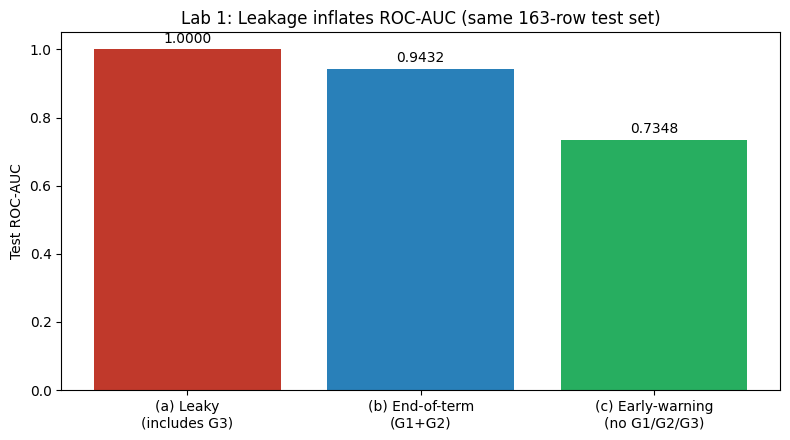

In [2]:
# Project 01 — Lab 1: Data Leakage
# Dataset: shared_dataset/dataset.csv (649 rows) | Target: pass = (G3 >= 10) | G3 never a feature

from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

ROOT = Path(__file__).resolve().parents[1]
OUT = Path(__file__).resolve().parent
NUMERIC = ["age", "Medu", "Fedu", "traveltime", "studytime", "failures",
           "famrel", "freetime", "goout", "Dalc", "Walc", "health", "absences"]
CATEGORICAL = ["school", "sex", "address", "famsize", "Pstatus", "Mjob", "Fjob",
               "reason", "guardian", "schoolsup", "famsup", "paid", "activities",
               "nursery", "higher", "internet", "romantic"]


def make_model(feature_cols):
    num = [c for c in feature_cols if c in NUMERIC + ["G1", "G2", "G3"]]
    cat = [c for c in feature_cols if c in CATEGORICAL]
    pre = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                          ("sc", StandardScaler())]), num),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat),
    ])
    return Pipeline([("pre", pre),
                     ("clf", RandomForestClassifier(n_estimators=200, random_state=42))])


def main():
    df = pd.read_csv(ROOT / "shared_dataset" / "dataset.csv", sep=";")
    y = (df["G3"] >= 10).astype(int)
    base = [c for c in df.columns if c != "G3"]          # default features incl. G1, G2
    variants = {
        "a_leaky_includes_G3": [c for c in df.columns],  # G3 itself = the mistake
        "b_end_of_term_G1_G2": base,
        "c_early_warning_no_G1_G2_G3": [c for c in base if c not in ("G1", "G2")],
    }
    X_train, X_test, y_train, y_test = train_test_split(
        df, y, test_size=0.25, random_state=42, stratify=y)
    lines = [f"Dataset: UCI Student Performance (student-por.csv), {len(df)} rows",
             f"Target: pass = (G3 >= 10); pass {(y == 1).sum()} ({y.mean():.1%}), "
             f"fail {(y == 0).sum()} ({1 - y.mean():.1%})",
             f"Split: stratified 75/25, seed 42; train {len(X_train)}, test {len(X_test)}",
             ""]
    results = {}
    for name, cols in variants.items():
        model = make_model(cols)
        model.fit(X_train[cols], y_train)
        proba = model.predict_proba(X_test[cols])[:, 1]
        pred = model.predict(X_test[cols])
        auc, acc = roc_auc_score(y_test, proba), accuracy_score(y_test, pred)
        results[name] = auc
        lines.append(f"{name}: n_features={len(cols)} ROC-AUC={auc:.4f} accuracy={acc:.4f}")
    lines += ["",
              "Timing argument: G3 is the final grade itself, so model (a) is not a "
              "predictor at all — it reads the answer. G1/G2 are earlier grades, so "
              "model (b) is legitimate only at the end of term, after those grades "
              "exist. For an early-warning model that must flag at-risk students at "
              "the START of the year, G1/G2 do not exist yet, so only model (c) is "
              "usable. The corrected, recommended pipeline for early warning is (c).",
              f"Leakage inflation (a minus c): {results['a_leaky_includes_G3'] - results['c_early_warning_no_G1_G2_G3']:.4f} ROC-AUC"]
    (OUT / "results").mkdir(exist_ok=True)
    (OUT / "results" / "results.txt").write_text("\n".join(lines) + "\n")
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.bar(["(a) Leaky\n(includes G3)", "(b) End-of-term\n(G1+G2)",
            "(c) Early-warning\n(no G1/G2/G3)"],
           [results[k] for k in variants], color=["#c0392b", "#2980b9", "#27ae60"])
    ax.set_ylabel("Test ROC-AUC"); ax.set_ylim(0, 1.05)
    ax.set_title("Lab 1: Leakage inflates ROC-AUC (same 163-row test set)")
    for bar, v in zip(ax.patches, results.values()):
        ax.text(bar.get_x() + bar.get_width() / 2, v + 0.02, f"{v:.4f}", ha="center")
    fig.tight_layout()
    fig.savefig(OUT / "visualizations" / "roc_auc_comparison.png", dpi=150)
    print("\n".join(lines))


if __name__ == "__main__":
    main()
